## 1. Environment and data loading

The input files are the schema-preserving outputs of `01_data_cleaning.ipynb`. The original SciFact files are retained separately under `data/scifact/`. All file paths are resolved relative to the repository root so this notebook can run from either the root directory or `notebooks/`.

The `train` and `dev` claim files include evidence annotations; the `test` claim file does not provide gold evidence labels.

In [1]:
from pathlib import Path
import json
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

REQUIRED = 'data/processed/corpus_clean.jsonl'
PROJECT_ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / REQUIRED).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Cleaned SciFact files not found. Run notebooks/01_data_cleaning.ipynb '
        'from the LitScope-Lite project directory first.'
    )

DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
IMAGE_DIR = PROJECT_ROOT / 'images'
REPORT_DIR = PROJECT_ROOT / 'outputs' / 'eda'
IMAGE_DIR.mkdir(exist_ok=True, parents=True)
REPORT_DIR.mkdir(exist_ok=True, parents=True)

INPUT_FILES = {
    'corpus': DATA_DIR / 'corpus_clean.jsonl',
    **{split: DATA_DIR / f'claims_{split}_clean.jsonl'
       for split in ('train', 'dev', 'test')},
}

def read_jsonl(path):
    with path.open('r', encoding='utf-8') as stream:
        return [json.loads(line) for line in stream if line.strip()]

records = {name: read_jsonl(path) for name, path in INPUT_FILES.items()}
corpus = records['corpus']
claims = {split: records[split] for split in ('train', 'dev', 'test')}
doc_lookup = {int(item['doc_id']): item for item in corpus}
assert len(doc_lookup) == len(corpus), 'Document IDs must be unique.'
assert all(isinstance(doc['abstract'], list) for doc in corpus)
assert all(set(('id', 'claim')).issubset(item) for split in claims for item in claims[split])

inventory = pd.DataFrame([
    {'Input file': INPUT_FILES[key].name, 'Records': len(records[key]),
     'Evidence available': 'Not applicable' if key == 'corpus'
      else ('Not provided' if key == 'test' else 'Yes')}
    for key in ('corpus', 'train', 'dev', 'test')
])
display(inventory)
print('Total abstract sentences:', f"{sum(len(doc['abstract']) for doc in corpus):,}")

,Input file,Records,Evidence available
0,corpus_clean.jsonl,5183,Not applicable
1,claims_train_clean.jsonl,809,Yes
2,claims_dev_clean.jsonl,300,Yes
3,claims_test_clean.jsonl,300,Not provided


Total abstract sentences: 45,952


## 2. Descriptive feature construction

Features are derived from cleaned text and existing annotations only. Word counts use whitespace-delimited tokens; lexical overlap is measured using lowercased alphanumeric token sets. These definitions are consistent across all splits.

**Unit of analysis:**

- **Document:** One SciFact abstract (`doc_id`).
- **Claim:** One claim (`id`) in a designated split.
- **Evidence annotation:** One labeled evidence set associated with a claim–document pair. A claim can have multiple evidence annotations, so annotation-level and claim-level counts are not interchangeable.

An empty `evidence` dictionary means *no gold evidence annotation is listed for that claim*. It is not treated as a verified `NOT_ENOUGH_INFO` class. No synthetic negative claim–document pairs are generated.

In [2]:
TOKEN_RE = re.compile(r"\b[\w]+(?:[-'][\w]+)*\b", flags=re.UNICODE)

def word_count(text):
    return len(str(text).split())

def tokens(text):
    return TOKEN_RE.findall(str(text).casefold())

def digit_token_ratio(text):
    items = tokens(text)
    return sum(any(char.isdigit() for char in item) for item in items) / len(items) if items else 0.0

def jaccard(text_a, text_b):
    a, b = set(tokens(text_a)), set(tokens(text_b))
    return len(a & b) / len(a | b) if (a or b) else 0.0

corpus_rows = []
sentence_rows = []
for doc in corpus:
    doc_id = int(doc['doc_id'])
    abstract = doc['abstract']
    joined_abstract = ' '.join(abstract)
    sentence_words = [word_count(s) for s in abstract]
    corpus_rows.append({
        'doc_id': doc_id,
        'title_word_count': word_count(doc.get('title', '')),
        'abstract_word_count': word_count(joined_abstract),
        'abstract_char_count': len(joined_abstract),
        'abstract_sentence_count': len(abstract),
        'mean_sentence_word_count': float(np.mean(sentence_words)) if sentence_words else np.nan,
        'max_sentence_word_count': max(sentence_words, default=0),
        'very_short_sentence_count': sum(n <= 2 for n in sentence_words),
        'repeated_sentence_occurrences': sum(count - 1 for count in Counter(abstract).values() if count > 1),
        'abstract_numeric_token_ratio': digit_token_ratio(joined_abstract),
        'structured': doc.get('structured'),
    })
    for position, sentence in enumerate(abstract):
        sentence_rows.append({'doc_id': doc_id, 'sentence_index': position,
                              'sentence_word_count': sentence_words[position]})

doc_df = pd.DataFrame(corpus_rows)
sentence_df = pd.DataFrame(sentence_rows)

claim_rows = []
evidence_rows = []
for split in ('train', 'dev', 'test'):
    for item in claims[split]:
        evidence = item.get('evidence', {}) if split != 'test' else {}
        claim_id = int(item['id'])
        claim_text = item['claim']
        claim_rows.append({
            'split': split, 'claim_id': claim_id,
            'claim_word_count': word_count(claim_text),
            'claim_char_count': len(claim_text),
            'claim_numeric_token_ratio': digit_token_ratio(claim_text),
            'cited_doc_count': len(item.get('cited_doc_ids', [])) if split != 'test' else np.nan,
            'has_gold_evidence': bool(evidence) if split != 'test' else np.nan,
            'annotated_doc_count': len(evidence) if split != 'test' else np.nan,
        })
        if split == 'test':
            continue
        for raw_doc_id, annotations in evidence.items():
            doc_id = int(raw_doc_id)
            if doc_id not in doc_lookup:
                raise ValueError(f'Broken evidence document reference: {doc_id}')
            abstract = doc_lookup[doc_id]['abstract']
            for annotation in annotations:
                indices = annotation['sentences']
                if any(not isinstance(idx, int) or idx < 0 or idx >= len(abstract) for idx in indices):
                    raise ValueError(f'Invalid evidence sentence index for document {doc_id}')
                rationale = ' '.join(abstract[idx] for idx in indices)
                abstract_text = ' '.join(abstract)
                evidence_rows.append({
                    'split': split, 'claim_id': claim_id, 'doc_id': doc_id,
                    'label': annotation['label'],
                    'claim_word_count': word_count(claim_text),
                    'abstract_word_count': word_count(abstract_text),
                    'abstract_sentence_count': len(abstract),
                    'rationale_sentence_count': len(indices),
                    'rationale_word_count': word_count(rationale),
                    'claim_numeric_token_ratio': digit_token_ratio(claim_text),
                    'abstract_numeric_token_ratio': digit_token_ratio(abstract_text),
                    'claim_rationale_jaccard': jaccard(claim_text, rationale),
                    'claim_abstract_jaccard': jaccard(claim_text, abstract_text),
                })

claim_df = pd.DataFrame(claim_rows)
evidence_df = pd.DataFrame(evidence_rows)
assert set(evidence_df['label']).issubset({'SUPPORT', 'CONTRADICT'})
assert len(doc_df) == len(corpus) and len(claim_df) == sum(len(v) for v in claims.values())
assert len(sentence_df) == sum(len(doc['abstract']) for doc in corpus)

print('Document-level descriptive features:', doc_df.shape)
print('Claim-level descriptive features:', claim_df.shape)
print('Evidence annotation-level features:', evidence_df.shape)
display(doc_df[['abstract_word_count', 'abstract_sentence_count',
               'very_short_sentence_count', 'repeated_sentence_occurrences']].describe().round(2))

Document-level descriptive features: (5183, 11)
Claim-level descriptive features: (1409, 8)
Evidence annotation-level features: (1295, 13)


,abstract_word_count,abstract_sentence_count,very_short_sentence_count,repeated_sentence_occurrences
count,5183.00,5183.00,5183.00,5183.00
mean,201.81,8.87,0.21,0.16
std,86.01,8.02,6.86,6.67
min,26.00,3.00,0.00,0.00
25%,147.00,6.00,0.00,0.00
50%,192.00,8.00,0.00,0.00
75%,247.00,11.00,0.00,0.00
max,1524.00,367.00,348.00,345.00


## 3. Evidence labels and annotation coverage

The first figure counts **evidence annotations**, not distinct claims. The second displays the proportion of **claims** with at least one listed gold evidence annotation. Claims without annotations are shown separately; they are not assigned a new stance label.

label,SUPPORT,CONTRADICT
Split,,
train,616,341
dev,216,122


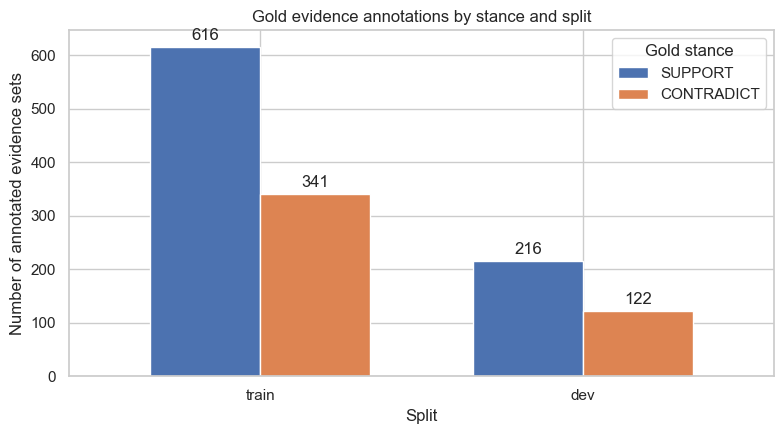

WindowsPath('c:/Users/muham/OneDrive/Desktop/ds_project/LitScope-Lite/images/02_01_gold_evidence_stance_counts.png')

In [3]:
def save_figure(filename):
    path = IMAGE_DIR / filename
    plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()
    return path

label_counts = (evidence_df.groupby(['split', 'label']).size()
                .unstack(fill_value=0)
                .reindex(index=['train', 'dev'], columns=['SUPPORT', 'CONTRADICT'], fill_value=0))
display(label_counts.rename_axis('Split'))

ax = label_counts.plot(kind='bar', figsize=(8, 4.5), rot=0, width=0.68)
ax.set(title='Gold evidence annotations by stance and split',
       xlabel='Split', ylabel='Number of annotated evidence sets')
ax.legend(title='Gold stance')
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
save_figure('02_01_gold_evidence_stance_counts.png')

has_gold_evidence,No listed gold evidence,At least one gold evidence set
split,,
train,304,505
dev,112,188


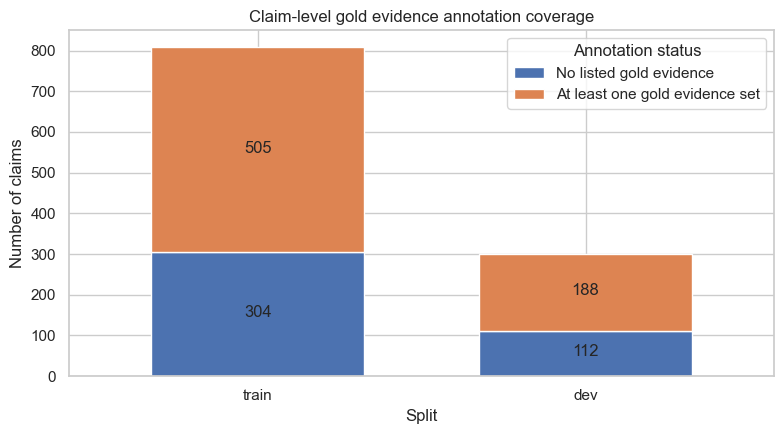

WindowsPath('c:/Users/muham/OneDrive/Desktop/ds_project/LitScope-Lite/images/02_02_claim_annotation_coverage.png')

In [4]:
coverage = (claim_df.loc[claim_df['split'].isin(['train', 'dev'])]
            .groupby(['split', 'has_gold_evidence']).size()
            .unstack(fill_value=0)
            .rename(columns={False: 'No listed gold evidence', True: 'At least one gold evidence set'})
            .reindex(index=['train', 'dev']))
display(coverage)

ax = coverage.plot(kind='bar', stacked=True, figsize=(8, 4.5), rot=0, width=0.65)
ax.set(title='Claim-level gold evidence annotation coverage',
       xlabel='Split', ylabel='Number of claims')
ax.legend(title='Annotation status', loc='upper right')
for container in ax.containers:
    ax.bar_label(container, label_type='center', padding=1)
plt.tight_layout()
save_figure('02_02_claim_annotation_coverage.png')

**Interpretation.** Stance class frequencies should be reported at a declared unit of analysis. The annotation distribution is relevant to class balance in later classification experiments, but the counts must not be conflated with the number of unique claims. Missing annotations are not negative training examples by default.

## 4. Claim length distribution

The comparison uses all three claim splits. Overlapping histograms provide a descriptive check for differences in input-text length; no split is used to fit any transformation.

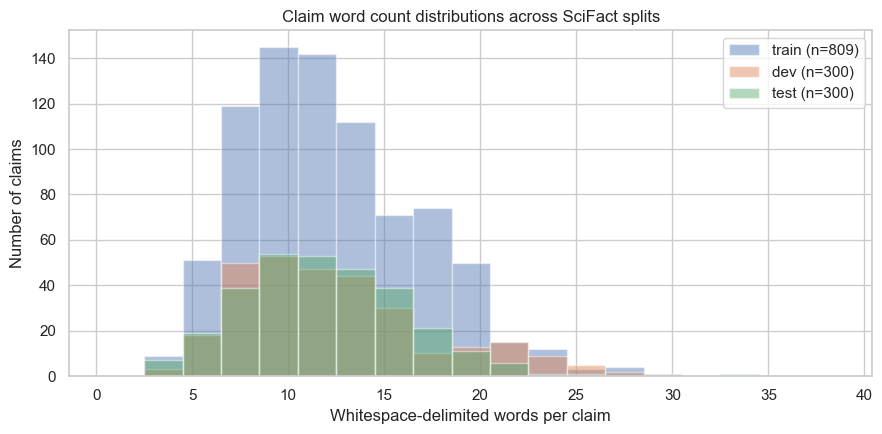

,count,mean,median,std,min,max
split,,,,,,
train,809,12.33,12.0,4.66,3,39
dev,300,12.51,12.0,5.14,4,29
test,300,12.06,12.0,4.56,4,39


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(0.5, int(claim_df['claim_word_count'].max()) + 1.5, 2)
for split in ('train', 'dev', 'test'):
    series = claim_df.loc[claim_df['split'] == split, 'claim_word_count']
    ax.hist(series, bins=bins, alpha=0.45, label=f'{split} (n={len(series)})')
ax.set(title='Claim word count distributions across SciFact splits',
       xlabel='Whitespace-delimited words per claim', ylabel='Number of claims')
ax.legend()
plt.tight_layout()
save_figure('02_03_claim_word_count_distribution.png')

display(claim_df.groupby('split')['claim_word_count']
        .agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
        .reindex(['train', 'dev', 'test']))

**Interpretation.** Claim length is described separately by split to identify obvious shifts in the benchmark. Length alone is not a stance signal, and this plot does not establish retrieval or classification performance.

## 5. Abstract length and sentence-count distributions

SciFact abstracts differ substantially in total length and segmentation. To avoid losing resolution in the main distribution, the axes of the following two charts are limited to the respective 99th percentile. The full range, including values outside the displayed axes, remains in the summary tables and exported data.

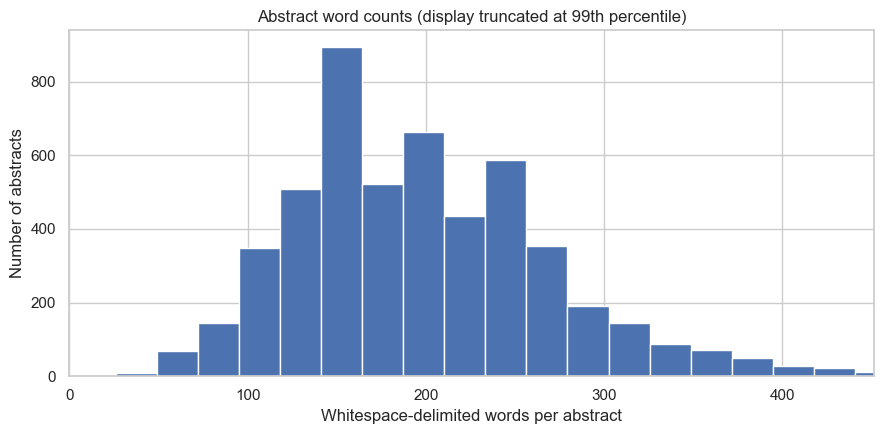

Abstract word counts: median=192, 99th percentile=451.5, maximum=1524


In [6]:
abstract_words = doc_df['abstract_word_count']
word_p99 = float(abstract_words.quantile(0.99))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(abstract_words, bins=65)
ax.set_xlim(0, word_p99)
ax.set(title='Abstract word counts (display truncated at 99th percentile)',
       xlabel='Whitespace-delimited words per abstract', ylabel='Number of abstracts')
plt.tight_layout()
save_figure('02_04_abstract_word_count_distribution.png')

print(f'Abstract word counts: median={abstract_words.median():.0f}, '
      f'99th percentile={word_p99:.1f}, maximum={abstract_words.max()}')

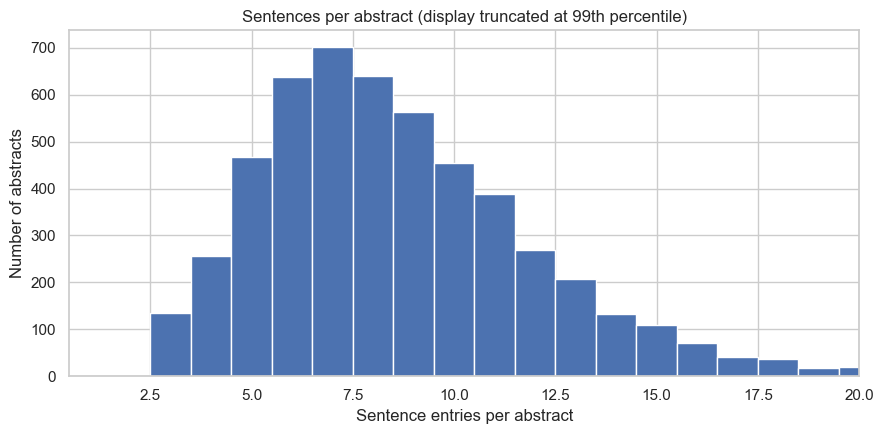

Abstract sentence counts: median=8, 99th percentile=20.0, maximum=367


In [7]:
abstract_sentences = doc_df['abstract_sentence_count']
sent_p99 = float(abstract_sentences.quantile(0.99))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(abstract_sentences, bins=np.arange(0.5, abstract_sentences.max() + 1.5, 1))
ax.set_xlim(0.5, sent_p99)
ax.set(title='Sentences per abstract (display truncated at 99th percentile)',
       xlabel='Sentence entries per abstract', ylabel='Number of abstracts')
plt.tight_layout()
save_figure('02_05_abstract_sentence_count_distribution.png')

print(f'Abstract sentence counts: median={abstract_sentences.median():.0f}, '
      f'99th percentile={sent_p99:.1f}, maximum={abstract_sentences.max()}')

**Interpretation.** The plots describe ordinary abstract lengths while preserving unusually large values for audit. Extremely large sentence counts can reflect source-document formatting problems rather than genuinely extensive scientific content; any such cases should be investigated using the quality flags generated during cleaning.

## 6. Claim length by annotated stance

This comparison uses train and development claims that have gold evidence. The data are deduplicated by `(split, claim_id, label)` so a claim with multiple annotations of the same stance contributes only once to that stance. A claim bearing both stances would appear once in each respective group.

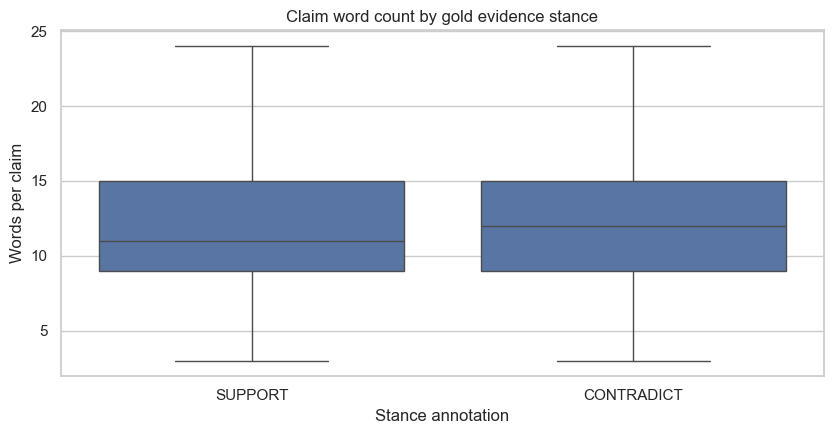

,count,median,mean,std
label,,,,
SUPPORT,456,11.0,12.09,4.60
CONTRADICT,237,12.0,12.33,4.75


In [8]:
claim_label_df = evidence_df[['split', 'claim_id', 'label', 'claim_word_count']].drop_duplicates()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.boxplot(data=claim_label_df, x='label', y='claim_word_count',
            order=['SUPPORT', 'CONTRADICT'], ax=ax, showfliers=False)
ax.set(title='Claim word count by gold evidence stance',
       xlabel='Stance annotation', ylabel='Words per claim')
plt.tight_layout()
save_figure('02_06_claim_length_by_annotated_stance.png')

display(claim_label_df.groupby('label')['claim_word_count']
        .agg(['count', 'median', 'mean', 'std']).round(2)
        .reindex(['SUPPORT', 'CONTRADICT']))

**Interpretation.** The boxplots compare basic linguistic complexity proxies across annotated stances. Whiskers and medians are descriptive; overlapping distributions should not be interpreted as predictive separability.

## 7. Evidence rationale length

The evidence annotations identify the source sentence indices used as rationales. The figure counts the number of sentences per labeled annotation, including any annotations with multi-sentence evidence.

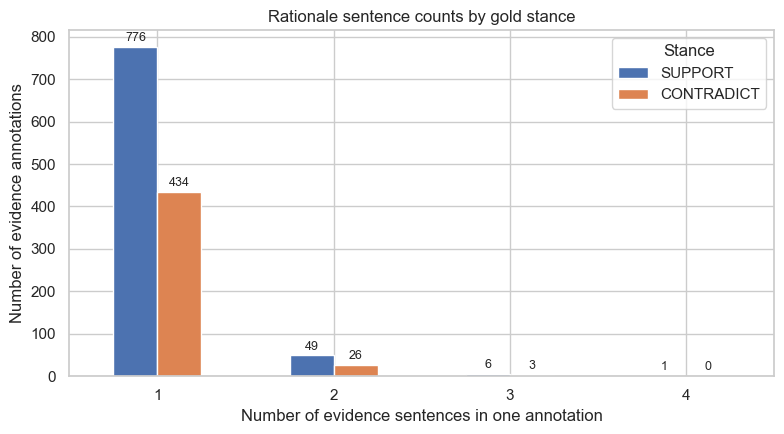

label,SUPPORT,CONTRADICT
rationale_sentence_count,,
1,776,434
2,49,26
3,6,3
4,1,0


In [9]:
rationale_counts = (evidence_df.groupby(['rationale_sentence_count', 'label']).size()
                    .unstack(fill_value=0)
                    .reindex(columns=['SUPPORT', 'CONTRADICT'], fill_value=0))
ax = rationale_counts.plot(kind='bar', figsize=(8, 4.5), rot=0)
ax.set(title='Rationale sentence counts by gold stance',
       xlabel='Number of evidence sentences in one annotation',
       ylabel='Number of evidence annotations')
ax.legend(title='Stance')
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=2)
plt.tight_layout()
save_figure('02_07_rationale_sentence_counts_by_stance.png')
display(rationale_counts)

**Interpretation.** The rationale-length distribution informs how many evidence sentences are typically supplied in the benchmark. It does not justify truncating or altering the reference sentence indices; all referenced sentences remain intact.

## 8. Lexical overlap between claims and gold rationales

Jaccard lexical overlap is the intersection divided by the union of unique casefolded alphanumeric tokens. This is a **descriptive, unscaled feature**, not a retrieval score. The calculation is restricted to existing gold-annotated claim–rationale pairs; it does not compare arbitrary claims against unrelated documents.

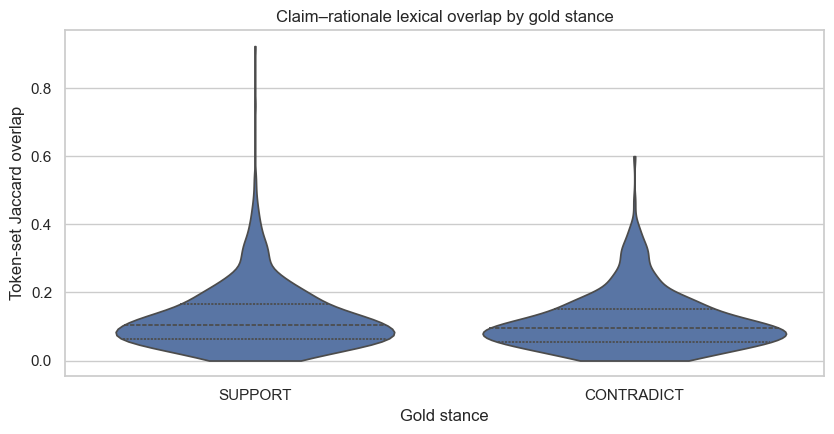

,count,mean,median,std,min,max
label,,,,,,
SUPPORT,832,0.125,0.105,0.096,0.0,0.923
CONTRADICT,463,0.113,0.095,0.085,0.0,0.600


In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.violinplot(data=evidence_df, x='label', y='claim_rationale_jaccard',
               order=['SUPPORT', 'CONTRADICT'], inner='quart', cut=0, ax=ax)
ax.set(title='Claim–rationale lexical overlap by gold stance',
       xlabel='Gold stance', ylabel='Token-set Jaccard overlap')
plt.tight_layout()
save_figure('02_08_claim_rationale_lexical_overlap.png')

display(evidence_df.groupby('label')['claim_rationale_jaccard']
        .agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(3)
        .reindex(['SUPPORT', 'CONTRADICT']))

**Interpretation.** The distributions indicate the extent to which relevant evidence repeats claim vocabulary. Lexical overlap does not determine entailment: supporting and contradicting evidence may both share terminology with the same claim.

## 9. Numerical meta-feature correlations

Spearman rank correlation is used because feature distributions may be skewed and include outliers. The calculation includes existing train/dev evidence annotations only. It does **not** imply causality, model performance, or complementarity between TF-IDF and dense embeddings; the cleaned data contain no paired retrieval-score measurements for that comparison.

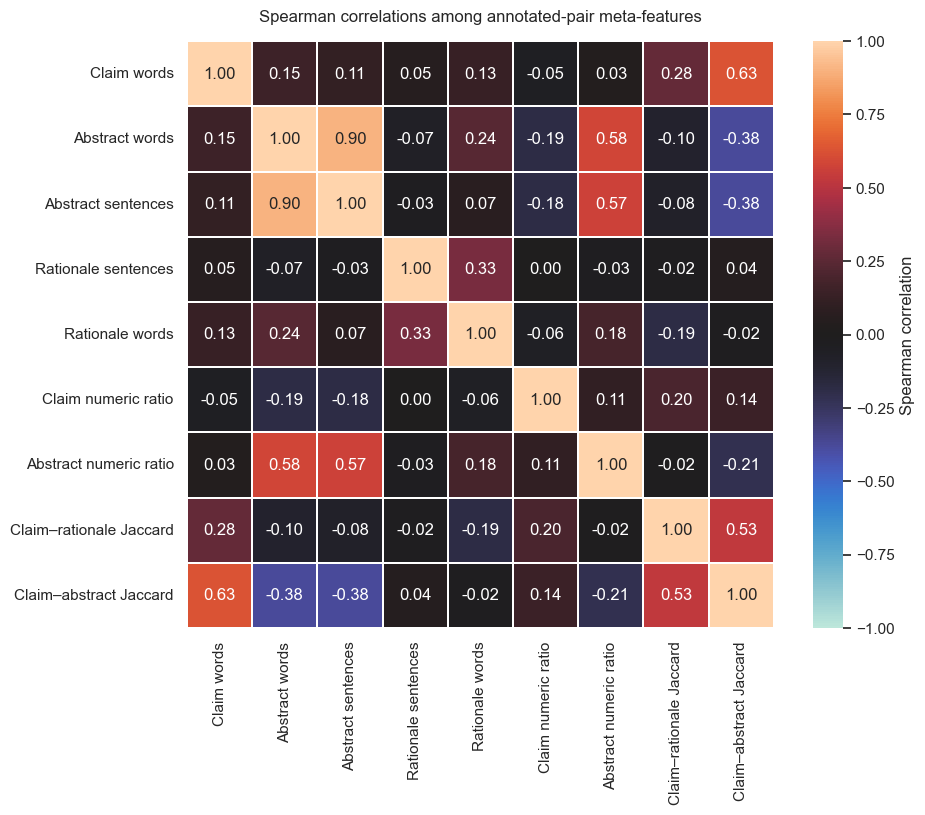

,Claim words,Abstract words,Abstract sentences,Rationale sentences,Rationale words,Claim numeric ratio,Abstract numeric ratio,Claim–rationale Jaccard,Claim–abstract Jaccard
Claim words,1.000,0.153,0.112,0.048,0.129,-0.046,0.034,0.278,0.627
Abstract words,0.153,1.000,0.900,-0.067,0.239,-0.185,0.584,-0.097,-0.376
Abstract sentences,0.112,0.900,1.000,-0.031,0.066,-0.184,0.568,-0.078,-0.378
Rationale sentences,0.048,-0.067,-0.031,1.000,0.332,0.002,-0.028,-0.017,0.039
Rationale words,0.129,0.239,0.066,0.332,1.000,-0.062,0.181,-0.187,-0.021
Claim numeric ratio,-0.046,-0.185,-0.184,0.002,-0.062,1.000,0.108,0.203,0.141
Abstract numeric ratio,0.034,0.584,0.568,-0.028,0.181,0.108,1.000,-0.015,-0.212
Claim–rationale Jaccard,0.278,-0.097,-0.078,-0.017,-0.187,0.203,-0.015,1.000,0.527
Claim–abstract Jaccard,0.627,-0.376,-0.378,0.039,-0.021,0.141,-0.212,0.527,1.000


In [11]:
feature_columns = [
    'claim_word_count', 'abstract_word_count', 'abstract_sentence_count',
    'rationale_sentence_count', 'rationale_word_count',
    'claim_numeric_token_ratio', 'abstract_numeric_token_ratio',
    'claim_rationale_jaccard', 'claim_abstract_jaccard',
]
feature_labels = {
    'claim_word_count': 'Claim words',
    'abstract_word_count': 'Abstract words',
    'abstract_sentence_count': 'Abstract sentences',
    'rationale_sentence_count': 'Rationale sentences',
    'rationale_word_count': 'Rationale words',
    'claim_numeric_token_ratio': 'Claim numeric ratio',
    'abstract_numeric_token_ratio': 'Abstract numeric ratio',
    'claim_rationale_jaccard': 'Claim–rationale Jaccard',
    'claim_abstract_jaccard': 'Claim–abstract Jaccard',
}
correlation = evidence_df[feature_columns].corr(method='spearman')
correlation.index = [feature_labels[col] for col in correlation.index]
correlation.columns = [feature_labels[col] for col in correlation.columns]
fig, ax = plt.subplots(figsize=(10, 8.2))
sns.heatmap(correlation, vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', linewidths=0.35,
            square=True, cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Spearman correlations among annotated-pair meta-features', pad=14)
plt.tight_layout()
save_figure('02_09_meta_feature_spearman_heatmap.png')
display(correlation.round(3))

**Interpretation.** Strongly correlated length features can contain redundant information, while weak correlations indicate distinct descriptive behavior. The matrix is conditional on gold-annotated pairs and may not represent arbitrary candidate claim–document pairs.

## 10. Cited-document count and dataset split overlap

`cited_doc_ids` is available only in the training and development claim files. Citation counts describe the number of documents associated with a claim; a cited document is not necessarily a labeled positive evidence document. Exact cross-split claim overlap is assessed after casefolding and whitespace normalization.

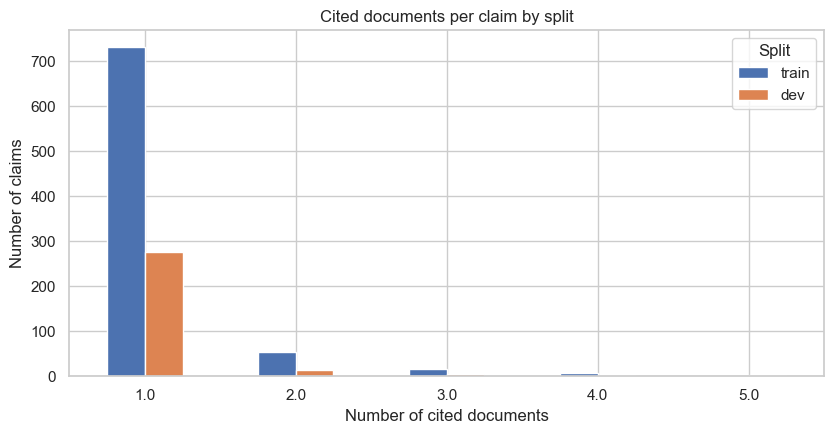

split,train,dev
cited_doc_count,,
1.0,732,276
2.0,53,15
3.0,16,4
4.0,7,3
5.0,1,2


,split_a,split_b,shared_distinct_claim_texts
0,train,dev,2
1,train,test,1
2,dev,test,0


In [12]:
citation_counts = (claim_df.loc[claim_df['split'].isin(['train', 'dev'])]
                   .groupby(['cited_doc_count', 'split']).size()
                   .unstack(fill_value=0)
                   .reindex(columns=['train', 'dev'], fill_value=0))
ax = citation_counts.plot(kind='bar', figsize=(8.5, 4.5), rot=0)
ax.set(title='Cited documents per claim by split',
       xlabel='Number of cited documents', ylabel='Number of claims')
ax.legend(title='Split')
plt.tight_layout()
save_figure('02_10_cited_documents_per_claim.png')
display(citation_counts)

def normalize_claim_for_overlap(text):
    return ' '.join(str(text).casefold().split())

split_claim_sets = {split: {normalize_claim_for_overlap(item['claim']) for item in claims[split]}
                    for split in ('train', 'dev', 'test')}
overlap_rows = []
for left, right in (('train', 'dev'), ('train', 'test'), ('dev', 'test')):
    overlap_rows.append({'split_a': left, 'split_b': right,
                         'shared_distinct_claim_texts': len(split_claim_sets[left] & split_claim_sets[right])})
overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)

**Interpretation.** Shared claim text across splits warrants inspection before later evaluation. This EDA reports overlap without moving or removing records, since the supplied benchmark split membership is preserved.

## 11. Quality indicators from the cleaning audit

The cleaning stage records potentially malformed or extreme sentence entries without removing them. Quality-flag counts can overlap (e.g., one sentence can be both very short and repeated), and should not be added together as though they count distinct affected sentences.

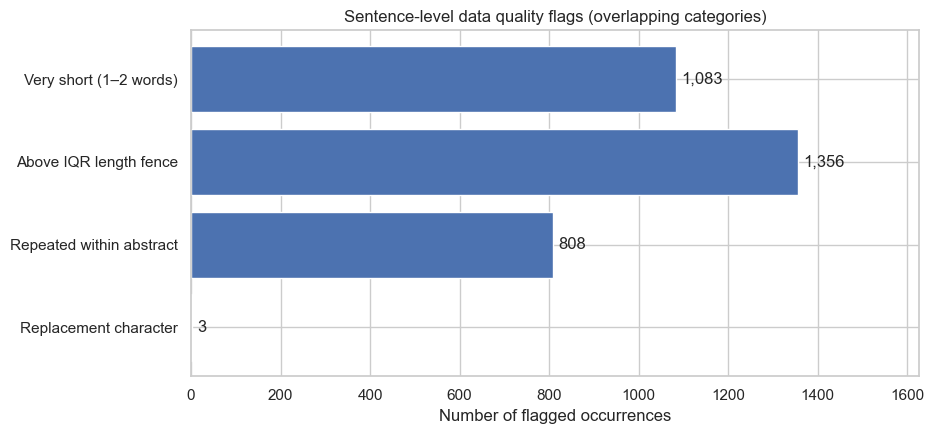

,flag,flagged_occurrences
0,Very short (1–2 words),1083
1,Above IQR length fence,1356
2,Repeated within abstract,808
3,Replacement character,3


Severely repetitive document IDs: [12207167, 36271512, 86217760]


In [13]:
with (DATA_DIR / 'cleaning_summary.json').open('r', encoding='utf-8') as stream:
    cleaning_summary = json.load(stream)
flag_counts = cleaning_summary['sentence_review_flag_counts']
quality_labels = {
    'very_short_1_or_2_words': 'Very short (1–2 words)',
    'above_sentence_length_IQR_fence': 'Above IQR length fence',
    'repeated_within_abstract': 'Repeated within abstract',
    'replacement_character_needs_review': 'Replacement character',
}
quality_df = pd.DataFrame([
    {'flag': quality_labels[name], 'flagged_occurrences': int(flag_counts[name])}
    for name in quality_labels
])
fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.barh(quality_df['flag'], quality_df['flagged_occurrences'])
ax.invert_yaxis()
ax.set(title='Sentence-level data quality flags (overlapping categories)',
       xlabel='Number of flagged occurrences', ylabel='')
for i, v in enumerate(quality_df['flagged_occurrences']):
    ax.text(v + 12, i, f'{v:,}', va='center')
ax.set_xlim(right=quality_df['flagged_occurrences'].max() * 1.2)
plt.tight_layout()
save_figure('02_11_sentence_quality_flag_counts.png')
display(quality_df)
print('Severely repetitive document IDs:', cleaning_summary['severe_repetition_doc_ids'])

## 12. Summary of empirical findings

The statements below are computed from the loaded data and use the appropriate observation unit. They distinguish documented observations from implications for later work.

In [14]:
train_coverage = coverage.loc['train']
dev_coverage = coverage.loc['dev']
stance_total = int(label_counts.values.sum())
support_total = int(label_counts['SUPPORT'].sum())
contradict_total = int(label_counts['CONTRADICT'].sum())
medians = evidence_df.groupby('label')['claim_rationale_jaccard'].median()
majority_rationale_ones = int((evidence_df['rationale_sentence_count'] == 1).sum())

# Find the highest absolute off-diagonal feature association for a compact summary.
abs_corr = correlation.abs().copy()
np.fill_diagonal(abs_corr.values, np.nan)
ranking = abs_corr.stack().sort_values(ascending=False)
strongest_a, strongest_b = ranking.index[0]
strongest_coef = float(correlation.loc[strongest_a, strongest_b])

summary = {
    'dataset': 'SciFact cleaned data (schema-preserving, 01_data_cleaning.ipynb)',
    'corpus_documents': len(doc_df),
    'abstract_sentences': len(sentence_df),
    'claims_by_split': {split: len(claims[split]) for split in ('train', 'dev', 'test')},
    'evidence_annotation_count_by_label': {'SUPPORT': support_total, 'CONTRADICT': contradict_total},
    'no_gold_evidence_listed_by_split': {
        split: int(coverage.loc[split, 'No listed gold evidence']) for split in ('train', 'dev')},
    'median_claim_word_count_by_split': {
        split: float(claim_df.loc[claim_df['split'] == split, 'claim_word_count'].median())
        for split in ('train', 'dev', 'test')},
    'median_abstract_word_count': float(abstract_words.median()),
    'median_abstract_sentence_count': float(abstract_sentences.median()),
    'single_sentence_rationale_count': majority_rationale_ones,
    'total_evidence_annotations': stance_total,
    'median_claim_rationale_jaccard_by_label': {
        key: float(val) for key, val in medians.items()},
    'highest_abs_spearman_feature_pair': [strongest_a, strongest_b],
    'highest_abs_spearman_coefficient': strongest_coef,
    'cross_split_exact_claim_text_overlap': overlap_rows,
    'severely_repetitive_doc_ids': cleaning_summary['severe_repetition_doc_ids'],
    'figures': sorted(p.name for p in IMAGE_DIR.glob('02_*.png')),
}

with (REPORT_DIR / 'eda_summary.json').open('w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

doc_df.to_csv(REPORT_DIR / 'document_descriptive_features.csv', index=False)
claim_df.to_csv(REPORT_DIR / 'claim_descriptive_features.csv', index=False)
evidence_df.to_csv(REPORT_DIR / 'gold_evidence_annotation_features.csv', index=False)
overlap_df.to_csv(REPORT_DIR / 'cross_split_claim_overlap.csv', index=False)

report = f"""
### Quantitative findings

1. **Corpus size.** The cleaned benchmark contains **{len(doc_df):,} documents** and **{len(sentence_df):,} abstract sentence entries**. The median abstract has **{abstract_words.median():.0f} words** distributed across **{abstract_sentences.median():.0f} sentence entries**.
2. **Claim length.** Median whitespace-delimited claim lengths are **{summary['median_claim_word_count_by_split']['train']:.0f}** words (train), **{summary['median_claim_word_count_by_split']['dev']:.0f}** (dev), and **{summary['median_claim_word_count_by_split']['test']:.0f}** (test).
3. **Stance-annotation distribution.** There are **{stance_total:,} labeled evidence annotations** across the train and dev splits: **{support_total:,} SUPPORT ({100 * support_total / stance_total:.1f}%)** and **{contradict_total:,} CONTRADICT ({100 * contradict_total / stance_total:.1f}%)**. These are annotation counts, not distinct claim counts.
4. **Incomplete gold evidence coverage.** **{int(train_coverage['No listed gold evidence']):,}/{int(train_coverage.sum()):,}** training claims ({100 * train_coverage['No listed gold evidence'] / train_coverage.sum():.1f}%) and **{int(dev_coverage['No listed gold evidence']):,}/{int(dev_coverage.sum()):,}** development claims ({100 * dev_coverage['No listed gold evidence'] / dev_coverage.sum():.1f}%) have no listed gold evidence annotation. This is **not equivalent to an annotated NEI class**.
5. **Rationale granularity.** **{majority_rationale_ones:,}/{stance_total:,}** ({100 * majority_rationale_ones / stance_total:.1f}%) gold evidence annotations reference a single abstract sentence; the remainder reference multiple sentences.
6. **Lexical overlap.** Median claim–rationale token-set Jaccard scores are **{medians.get('SUPPORT', float('nan')):.3f}** (SUPPORT) and **{medians.get('CONTRADICT', float('nan')):.3f}** (CONTRADICT). These overlapping distributions are descriptive and cannot determine stance on their own.
7. **Feature relationships.** The strongest absolute off-diagonal Spearman association in the annotation-level feature table is **{strongest_a} / {strongest_b}** (**ρ = {strongest_coef:.3f}**). Correlation here describes shared variation and does not validate a retrieval model.
8. **Split overlap.** Exact normalized claim-text overlap occurs for **{overlap_df.loc[0, 'shared_distinct_claim_texts']}** train–dev, **{overlap_df.loc[1, 'shared_distinct_claim_texts']}** train–test, and **{overlap_df.loc[2, 'shared_distinct_claim_texts']}** dev–test distinct claim strings. These cases should be considered when interpreting later evaluation results.
9. **Data quality.** Three documents are flagged for severe sentence repetition: **{', '.join(map(str, cleaning_summary['severe_repetition_doc_ids']))}**. Suspicious records were not removed and original evidence sentence indices remain unchanged.

### Interpretation boundaries

- All calculations are descriptive; no train/validation fit, normalization, classifier, or retrieved negative candidate generation occurs here.
- The SciFact test claims do not include gold evidence annotations in the uploaded file.
- The correlation heatmap contains linguistic meta-features only. TF-IDF and dense retriever scores were not available as paired observations in the cleaned files and are not invented for this report.
"""
display(Markdown(report))
print(f"Exported {len(summary['figures'])} figures to: {IMAGE_DIR}")
print(f'Exported feature tables and summary to: {REPORT_DIR}')


### Quantitative findings

1. **Corpus size.** The cleaned benchmark contains **5,183 documents** and **45,952 abstract sentence entries**. The median abstract has **192 words** distributed across **8 sentence entries**.
2. **Claim length.** Median whitespace-delimited claim lengths are **12** words (train), **12** (dev), and **12** (test).
3. **Stance-annotation distribution.** There are **1,295 labeled evidence annotations** across the train and dev splits: **832 SUPPORT (64.2%)** and **463 CONTRADICT (35.8%)**. These are annotation counts, not distinct claim counts.
4. **Incomplete gold evidence coverage.** **304/809** training claims (37.6%) and **112/300** development claims (37.3%) have no listed gold evidence annotation. This is **not equivalent to an annotated NEI class**.
5. **Rationale granularity.** **1,210/1,295** (93.4%) gold evidence annotations reference a single abstract sentence; the remainder reference multiple sentences.
6. **Lexical overlap.** Median claim–rationale token-set Jaccard scores are **0.105** (SUPPORT) and **0.095** (CONTRADICT). These overlapping distributions are descriptive and cannot determine stance on their own.
7. **Feature relationships.** The strongest absolute off-diagonal Spearman association in the annotation-level feature table is **Abstract sentences / Abstract words** (**ρ = 0.900**). Correlation here describes shared variation and does not validate a retrieval model.
8. **Split overlap.** Exact normalized claim-text overlap occurs for **2** train–dev, **1** train–test, and **0** dev–test distinct claim strings. These cases should be considered when interpreting later evaluation results.
9. **Data quality.** Three documents are flagged for severe sentence repetition: **12207167, 36271512, 86217760**. Suspicious records were not removed and original evidence sentence indices remain unchanged.

### Interpretation boundaries

- All calculations are descriptive; no train/validation fit, normalization, classifier, or retrieved negative candidate generation occurs here.
- The SciFact test claims do not include gold evidence annotations in the uploaded file.
- The correlation heatmap contains linguistic meta-features only. TF-IDF and dense retriever scores were not available as paired observations in the cleaned files and are not invented for this report.


Exported 11 figures to: c:\Users\muham\OneDrive\Desktop\ds_project\LitScope-Lite\images
Exported feature tables and summary to: c:\Users\muham\OneDrive\Desktop\ds_project\LitScope-Lite\outputs\eda


## 13. Output integrity checks

The descriptive tables and exported plots must be reproducible from the cleaned inputs. The following checks confirm that record counts, split attribution, and available gold label categories remain intact.

In [15]:
assert len(doc_df) == 5183, 'Unexpected number of corpus documents.'
assert {'train': 809, 'dev': 300, 'test': 300} == summary['claims_by_split'], 'Unexpected split sizes.'
assert len(sentence_df) == 45952, 'Unexpected abstract sentence count.'
assert evidence_df['split'].isin(['train', 'dev']).all(), 'Test data must not have gold evidence.'
assert set(evidence_df['label']) == {'SUPPORT', 'CONTRADICT'}, 'Unexpected evidence label.'
assert len(list(IMAGE_DIR.glob('02_*.png'))) == 11, 'Missing visualizations.'
assert all((REPORT_DIR / name).is_file() for name in (
    'document_descriptive_features.csv', 'claim_descriptive_features.csv',
    'gold_evidence_annotation_features.csv', 'cross_split_claim_overlap.csv',
    'eda_summary.json'))
print('PASS — Dataset and split sizes match the cleaned inputs.')
print('PASS — Evidence annotations are confined to the train and dev splits.')
print('PASS — Eleven EDA figures are available in images/.')
print('PASS — Descriptive feature tables and JSON summary have been saved.')

PASS — Dataset and split sizes match the cleaned inputs.
PASS — Evidence annotations are confined to the train and dev splits.
PASS — Eleven EDA figures are available in images/.
PASS — Descriptive feature tables and JSON summary have been saved.
